```
Analysis of Diabetic Retinopathy Fundus Imagery using Lightweight Convolutional Neural Networks
Modelling Implementation
Date: April 22nd, 2026
Author: Liam Tingley
Professor: Dr. Sazia Mahfuz
Course: COMP-3503 - Data Analytics
```

Importing the relevant modules.

In [1]:
# Importing modules.
import os
from google.colab import drive
from google.colab import files
import numpy as np
from skimage.io import imread
from keras.utils import set_random_seed
from tensorflow.config.experimental import enable_op_determinism

drive.mount('/content/drive')

Mounted at /content/drive


Fixing the seed value.

In [2]:
# Setting seed.
def setSeed(seed: int) -> int:
  SEED = seed
  set_random_seed(seed)
  enable_op_determinism()
  return SEED

In [3]:
# Utility functions for importing training, validation, and testing datasets into program.
import tensorflow as tf

def compileTrainingAndValidationSets(seedVal: int):

  dataset = tf.keras.utils.image_dataset_from_directory

  trainingSet = dataset(
      '/content/drive/MyDrive/Acadia University Files/2023 24/Winter Semester/COMP-3503/PreparedData2/train',
      image_size=(224, 224),
      batch_size=32,

      shuffle=True,
      seed=seedVal,
      label_mode='categorical'
  )

  validSet = tf.keras.utils.image_dataset_from_directory(
      "/content/drive/MyDrive/Acadia University Files/2023 24/Winter Semester/COMP-3503/PreparedData2/valid",
      image_size=(224, 224),
      batch_size=32,

      shuffle=True,
      seed=seedVal,
      label_mode='categorical'
  )

  return trainingSet, validSet

def compileTestSet():
  return tf.keras.utils.image_dataset_from_directory(
      "/content/drive/MyDrive/Acadia University Files/2023 24/Winter Semester/COMP-3503/PreparedData2/test",
      image_size=(224, 224),
      batch_size=32,

      shuffle=False,
      label_mode='categorical'
  )

In [4]:
# Configuring augmentation sequence.
from tensorflow.keras import layers

def augmentationSequence(seedVal: int) -> tf.keras.Sequential:
  return tf.keras.Sequential([
      layers.RandomFlip("horizontal", seed=seedVal),
      layers.RandomRotation(factor=(-0.04, 0.04), seed=seedVal),
      layers.RandomTranslation(0.02, 0.02, seed=seedVal),
      layers.RandomZoom(0.05, seed=seedVal)
  ])

In [5]:
# Importing Keras modules.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, BatchNormalization, Activation, MaxPooling2D, Flatten, Rescaling, GlobalMaxPool2D, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Creating the model.
def buildModel(dataAugmentation: Sequential) -> Sequential:
  modelLayers = [dataAugmentation,
                 Rescaling(1./255),

                 # Model Architecture.
                  Conv2D(64, kernel_size=5, activation="relu", input_shape=(224,224,1)),
                  # MaxPooling2D(pool_size=(3, 3), padding="same"),
                  Conv2D(32, kernel_size=7, activation="relu", input_shape=(224,224,1)),
                  # MaxPooling2D(pool_size=(2, 2), padding="same"),
                  Conv2D(32, kernel_size=13, activation="relu", input_shape=(224,224,1)),
                  GlobalMaxPool2D(),
                  Dense(2, activation="sigmoid"),
                 ]
  model = Sequential(modelLayers)

  return model

# Adding a stopping mechanism (patience = number of epochs with no improvement before stopping).
def addEarlyStopping() -> EarlyStopping:
  return EarlyStopping(
      monitor='val_loss',
      patience=5,
      restore_best_weights=True
  )

# Compiling the model using accuracy as performance metric.
from tensorflow.keras import optimizers

def configureOptimizer():
  return optimizers.Adam(learning_rate=0.0001)

In [6]:
# Modelling architectures to test:

# Base Model
# Conv2D(64, kernel_size=3, activation="relu", input_shape=(224,224,1)),
# Conv2D(32, kernel_size=3, activation="relu", input_shape=(224,224,1)),
# Flatten(),
# Dense(2, activation="sigmoid"),

# One Convolution Layer Model
# Conv2D(64, kernel_size=3, activation="relu", input_shape=(224,224,1)),
# Flatten(),
# Dense(2, activation="sigmoid"),

# Max Pooling Model 1
# Conv2D(64, kernel_size=5, activation="relu", input_shape=(224,224,1)),
# MaxPooling2D(pool_size=(3, 3), padding="same"),
# Conv2D(32, kernel_size=3, activation="relu", input_shape=(224,224,1)),
# Flatten(),
# Dense(2, activation="sigmoid"),

# Global Max Pooling Model
# Conv2D(64, kernel_size=5, activation="relu", input_shape=(224,224,1)),
# MaxPooling2D(pool_size=(3, 3), padding="same"),
# Conv2D(32, kernel_size=7, activation="relu", input_shape=(224,224,1)),
# MaxPooling2D(pool_size=(2, 2), padding="same"),
# Conv2D(32, kernel_size=13, activation="relu", input_shape=(224,224,1)),
# GlobalMaxPool2D(),
# Dense(2, activation="sigmoid"),

# Dropout + Kernel Sizing Adjustments (NOT INCLUDED IN FINAL PAPER)
# Conv2D(32, kernel_size=5, input_shape=(224,224,1), use_bias=False),
# BatchNormalization(),
# Activation('relu'),
# MaxPooling2D(pool_size=(3, 3), padding="same"),

# Conv2D(64, kernel_size=7, use_bias=False),
# BatchNormalization(),
# Activation('relu') ,
# MaxPooling2D(pool_size=(2, 2), padding="same"),
# Dropout(0.3),

# Conv2D(128, kernel_size=9, use_bias=False),
# BatchNormalization(),
# Activation('relu'),
# GlobalMaxPool2D(),

# Dense(2, activation="sigmoid"),

Compiling the model using the Adam optimizer, with a binary cross entropy loss function.

In [7]:
def compileModel(model: Sequential, optimizerArg) -> Sequential:
  model.compile(optimizer=optimizerArg, loss="categorical_crossentropy", metrics=["accuracy"])
  return model

In [8]:
# Training the model.
def trainModel(model, trainingSet, validationSet, callbacksArg, epochsArg: int):
  return model.fit(trainingSet, validation_data=validationSet, callbacks=callbacksArg, epochs=epochsArg)

In [9]:
# Visualizations.
import matplotlib.pyplot as plt

def plotAccuracyCurve(history):
  # Summarizing the model's accuracy history.
  plt.plot(history.history['accuracy'])
  plt.plot(history.history['val_accuracy'])
  plt.title('model accuracy')
  plt.ylabel('accuracy')
  plt.xlabel('epoch')
  plt.legend(['Train', 'Validation'], loc='upper left')
  plt.show()

def plotLossCurve(history):
  # Summarizing the model's loss history.
  plt.plot(history.history['loss'])
  plt.plot(history.history['val_loss'])
  plt.title('model loss')
  plt.ylabel('loss')
  plt.xlabel('epoch')
  plt.legend(['Train', 'Validation'], loc='upper left')
  plt.show()

In [10]:
# Evaluating the model on the test set.
def evaluateModel(model: Sequential, testSet):
  loss, accuracy = model.evaluate(testSet)
  return accuracy

In [11]:
# Generating a set of predictions for confusion matrix creation.
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def generateResults(model: Sequential, testSet):
  predictionProbs = model.predict(testSet)
  predictions = np.argmax(predictionProbs, axis=1)
  predictionsTrue = np.concatenate([y for x, y in testSet], axis=0)

  # Convert predictionsTrue to single integer labels from one-hot encoding
  predictionsTrue_labels = np.argmax(predictionsTrue, axis=1)

  confusionMatrix = confusion_matrix(predictionsTrue_labels, predictions)
  classificationReport = classification_report(predictionsTrue_labels, predictions)

  return confusionMatrix, classificationReport

In [12]:
# For storing performance data in a container class.
class PerformanceData:

  seed: int
  model: Sequential
  accuracy: float
  recall: float
  precision: float
  f1Score: float
  confusionMatrix: list

  def __init__(self, seed: int, model: Sequential, accuracy: float, recall: float, precision: float, f1Score: float, confusionMatrix: list, classificationReport: list):
    self.seed = seed
    self.model = model
    self.accuracy = accuracy
    self.recall = recall
    self.precision = precision
    self.f1Score = f1Score
    self.confusionMatrix = confusionMatrix
    self.classificationReport = classificationReport

In [13]:
# Running full end-to-end modelling pipeline via one function call.
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

def runPipeline(seedArg: int):
  # Setting seed value.
  SEED = setSeed(seedArg)
  print("LOCATING DATASETS...")

  # Compiling training, validation, and test sets.
  trainingSet, validSet = compileTrainingAndValidationSets(SEED)
  testSet = compileTestSet()

  # Building and compiling the model.
  print("CREATING + COMPILING MODEL...")
  dataAugmentation = augmentationSequence(SEED)

  model = buildModel(dataAugmentation)
  model = compileModel(model, configureOptimizer())

  # Training the model.
  print("TRAINING MODEL...")
  history = trainModel(model, trainingSet, validSet, [addEarlyStopping()], 40)

  print("EVALUATING MODEL...")
  accuracy = round(evaluateModel(model, testSet) * 100, 2)
  confusionMatrix, classificationReport = generateResults(model, testSet)
  recall = round(confusionMatrix[1][1] / (confusionMatrix[1][1] + confusionMatrix[1][0]) * 100, 2)
  precision = round(confusionMatrix[1][1] / (confusionMatrix[1][1] + confusionMatrix[0][1]) * 100, 2)
  f1Score = round(2 * (precision * recall) / (precision + recall) * 100, 2)

  # Displaying results.
  print("DISPLAYING RESULTS...")
  print("PLOTTING PERFORMANCE...")
  plotAccuracyCurve(history)
  plotLossCurve(history)
  print("PERFORMANCE METRICS...")
  print(f"Test Accuracy: {accuracy}%")
  print(f"Recall: {recall}%")
  print(f"Precision: {precision}%")
  print(f"F1 Score: {f1Score}%")
  print(f"Confusion Matrix:\n{confusionMatrix}")
  print(f"Classification Report:\n{classificationReport}")

  performanceData = PerformanceData(SEED, model, accuracy, recall, precision, f1Score, confusionMatrix, classificationReport)
  print("PERFORMANCE RECORDED!")
  return performanceData


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


LOCATING DATASETS...
Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
CREATING + COMPILING MODEL...
TRAINING MODEL...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 712s 11s/step - accuracy: 0.5482 - loss: 0.6924 - val_accuracy: 0.4614 - val_loss: 0.6902
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 31s 470ms/step - accuracy: 0.5862 - loss: 0.6765 - val_accuracy: 0.8060 - val_loss: 0.6392
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 435ms/step - accuracy: 0.7861 - loss: 0.5782 - val_accuracy: 0.8154 - val_loss: 0.4793
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 437ms/step - accuracy: 0.8179 - loss: 0.4451 - val_accuracy: 0.8117 - val_loss: 0.4077
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 448ms/step - accuracy: 0.8141 - loss: 0.4076 - val_accuracy: 0.8136 - val_loss: 0.4123
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 41s 447ms/step - accuracy: 0.8160 - loss: 0.4013 - val_accuracy: 0.8098 - val_loss: 0.3866
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 450ms/step - accuracy: 0.8300 - loss: 0.3880 - val_accuracy: 0.8041 - val_loss: 0.3858
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 435ms/step - accuracy: 0.8300 - loss: 0.3856 - val_accuracy: 0.8041

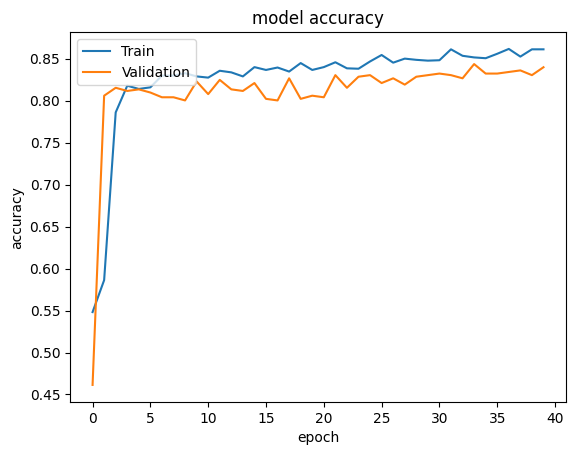

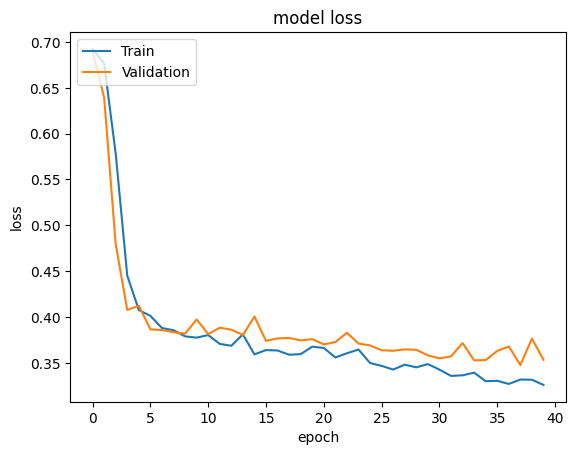

PERFORMANCE METRICS...
Test Accuracy: 87.45%
Recall: 88.5%
Precision: 86.21%
F1 Score: 8734.0%
Confusion Matrix:
[[102  16]
 [ 13 100]]
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.88       118
           1       0.86      0.88      0.87       113

    accuracy                           0.87       231
   macro avg       0.87      0.87      0.87       231
weighted avg       0.87      0.87      0.87       231

PERFORMANCE RECORDED!
LOCATING DATASETS...
Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
CREATING + COMPILING MODEL...
TRAINING MODEL...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 33s 466ms/step - accuracy: 0.5145 - loss: 0.6928 - val_accuracy: 0.7947 - val_loss: 0.6909
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 444ms/step - accuracy: 0.6219 - loss: 0.6832 - val_accuracy: 0.4802 - val_loss: 0.6728
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 433ms/step - accuracy: 0.6758 - loss: 0.6284 - val_accuracy: 0.5480 - val_loss: 0.6235
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 448ms/step - accuracy: 0.7693 - loss: 0.5358 - val_accuracy: 0.8154 - val_loss: 0.4767
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 442ms/step - accuracy: 0.7934 - loss: 0.4673 - val_accuracy: 0.8023 - val_loss: 0.4561
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 439ms/step - accuracy: 0.8165 - loss: 0.4234 - val_accuracy: 0.8098 - val_loss: 0.4025
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 30s 455ms/step - accuracy: 0.8170 - loss: 0.4059 - val_accuracy: 0.8136 - val_loss: 0.4303
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 440ms/step - accuracy: 0.8271 - loss: 0.4040 - val_accuracy: 0.809

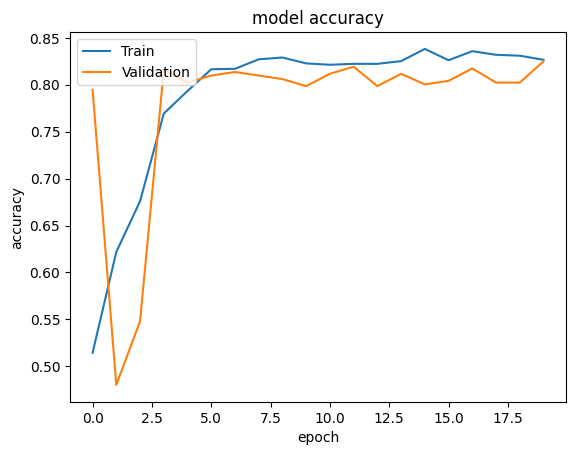

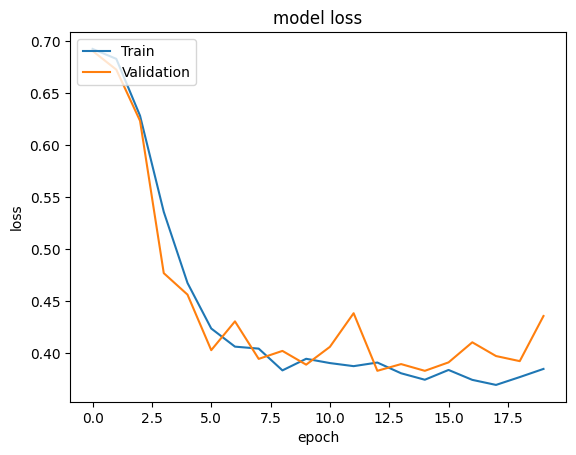

PERFORMANCE METRICS...
Test Accuracy: 83.55%
Recall: 85.84%
Precision: 81.51%
F1 Score: 8361.9%
Confusion Matrix:
[[96 22]
 [16 97]]
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.81      0.83       118
           1       0.82      0.86      0.84       113

    accuracy                           0.84       231
   macro avg       0.84      0.84      0.84       231
weighted avg       0.84      0.84      0.84       231

PERFORMANCE RECORDED!
LOCATING DATASETS...
Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
CREATING + COMPILING MODEL...
TRAINING MODEL...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 32s 450ms/step - accuracy: 0.5053 - loss: 0.6929 - val_accuracy: 0.5386 - val_loss: 0.6913
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 446ms/step - accuracy: 0.5877 - loss: 0.6858 - val_accuracy: 0.8041 - val_loss: 0.6646
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 439ms/step - accuracy: 0.7303 - loss: 0.6144 - val_accuracy: 0.8041 - val_loss: 0.5345
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 440ms/step - accuracy: 0.8030 - loss: 0.4798 - val_accuracy: 0.8060 - val_loss: 0.4328
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 42s 447ms/step - accuracy: 0.8054 - loss: 0.4269 - val_accuracy: 0.8041 - val_loss: 0.4143
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 450ms/step - accuracy: 0.8126 - loss: 0.4064 - val_accuracy: 0.8098 - val_loss: 0.4225
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 433ms/step - accuracy: 0.8271 - loss: 0.3945 - val_accuracy: 0.8117 - val_loss: 0.4031
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 442ms/step - accuracy: 0.8136 - loss: 0.3883 - val_accuracy: 0.807

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step
DISPLAYING RESULTS...
PLOTTING PERFORMANCE...


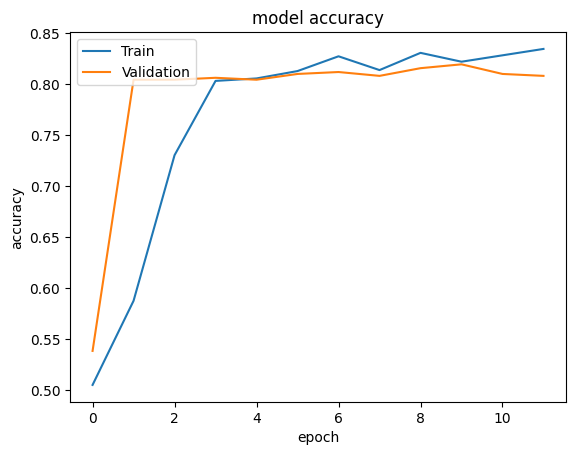

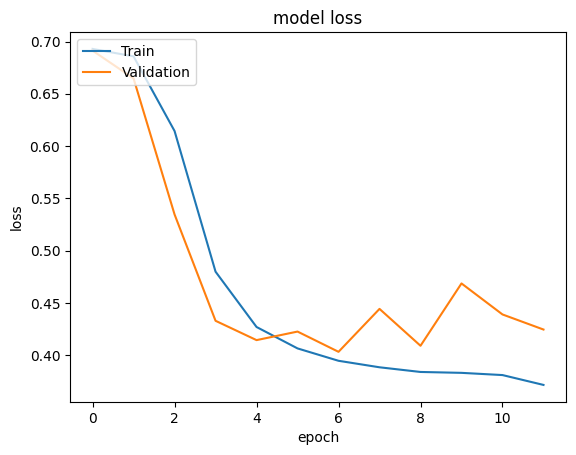

PERFORMANCE METRICS...
Test Accuracy: 84.85%
Recall: 85.84%
Precision: 83.62%
F1 Score: 8471.55%
Confusion Matrix:
[[99 19]
 [16 97]]
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       118
           1       0.84      0.86      0.85       113

    accuracy                           0.85       231
   macro avg       0.85      0.85      0.85       231
weighted avg       0.85      0.85      0.85       231

PERFORMANCE RECORDED!
LOCATING DATASETS...
Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
CREATING + COMPILING MODEL...
TRAINING MODEL...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 34s 480ms/step - accuracy: 0.5222 - loss: 0.6925 - val_accuracy: 0.7608 - val_loss: 0.6902
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 448ms/step - accuracy: 0.6609 - loss: 0.6728 - val_accuracy: 0.8079 - val_loss: 0.6323
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 445ms/step - accuracy: 0.7779 - loss: 0.5581 - val_accuracy: 0.7985 - val_loss: 0.4549
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 449ms/step - accuracy: 0.8097 - loss: 0.4310 - val_accuracy: 0.7928 - val_loss: 0.4029
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 448ms/step - accuracy: 0.8160 - loss: 0.4117 - val_accuracy: 0.8004 - val_loss: 0.4091
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 447ms/step - accuracy: 0.8218 - loss: 0.3990 - val_accuracy: 0.7966 - val_loss: 0.3925
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 445ms/step - accuracy: 0.8203 - loss: 0.3864 - val_accuracy: 0.8098 - val_loss: 0.4026
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 445ms/step - accuracy: 0.8271 - loss: 0.3818 - val_accuracy: 0.804

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
DISPLAYING RESULTS...
PLOTTING PERFORMANCE...


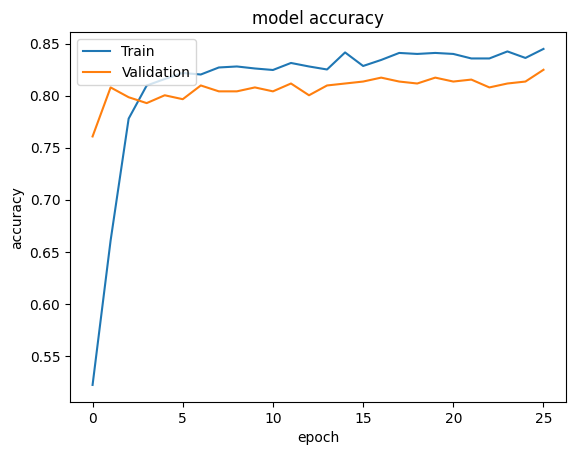

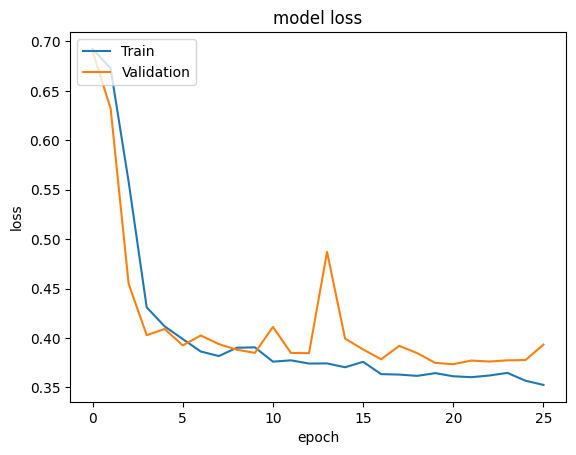

PERFORMANCE METRICS...
Test Accuracy: 86.15%
Recall: 86.73%
Precision: 85.22%
F1 Score: 8596.84%
Confusion Matrix:
[[101  17]
 [ 15  98]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86       118
           1       0.85      0.87      0.86       113

    accuracy                           0.86       231
   macro avg       0.86      0.86      0.86       231
weighted avg       0.86      0.86      0.86       231

PERFORMANCE RECORDED!
LOCATING DATASETS...
Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
CREATING + COMPILING MODEL...
TRAINING MODEL...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 33s 449ms/step - accuracy: 0.5544 - loss: 0.6928 - val_accuracy: 0.4614 - val_loss: 0.6919
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 436ms/step - accuracy: 0.6118 - loss: 0.6818 - val_accuracy: 0.4614 - val_loss: 0.6678
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 438ms/step - accuracy: 0.6980 - loss: 0.6097 - val_accuracy: 0.7759 - val_loss: 0.5225
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 440ms/step - accuracy: 0.7770 - loss: 0.4946 - val_accuracy: 0.8079 - val_loss: 0.4959
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 41s 443ms/step - accuracy: 0.8068 - loss: 0.4420 - val_accuracy: 0.8060 - val_loss: 0.4051
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 41s 442ms/step - accuracy: 0.8165 - loss: 0.4110 - val_accuracy: 0.8079 - val_loss: 0.4581
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 29s 438ms/step - accuracy: 0.8150 - loss: 0.4091 - val_accuracy: 0.8041 - val_loss: 0.3939
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 28s 435ms/step - accuracy: 0.8266 - loss: 0.3885 - val_accuracy: 0.809

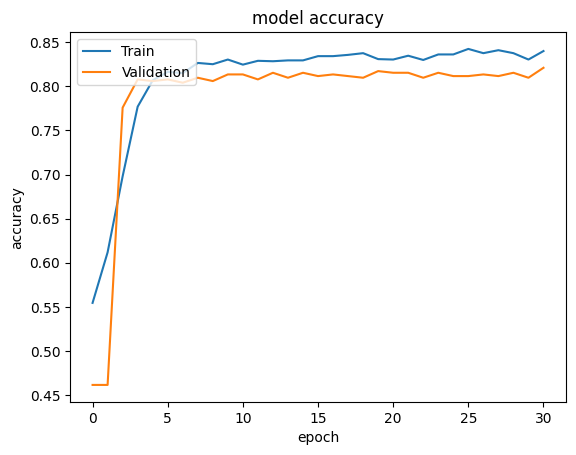

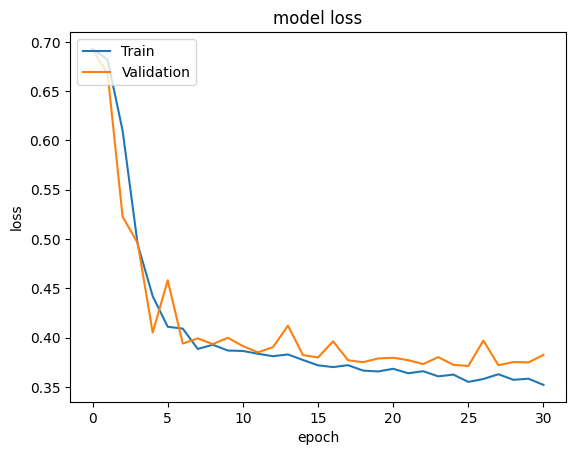

PERFORMANCE METRICS...
Test Accuracy: 83.98%
Recall: 87.61%
Precision: 81.15%
F1 Score: 8425.64%
Confusion Matrix:
[[95 23]
 [14 99]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.81      0.84       118
           1       0.81      0.88      0.84       113

    accuracy                           0.84       231
   macro avg       0.84      0.84      0.84       231
weighted avg       0.84      0.84      0.84       231

PERFORMANCE RECORDED!


In [14]:
# Running model pipeline on five seeds.
runList: list[PerformanceData] = []

for i in range(5):
  runData = runPipeline(i)
  runList.append(runData)

In [16]:
# Saving model.
# model.save("/content/drive/MyDrive/Acadia University Files/2023 24/Winter Semester/COMP-3503/Revised Paper Models/best_model.keras")

In [17]:
# MAKE SURE TO ADJUST INDEX AND SAVE FILE FOR EACH ARCHITECTURE.
peakPerformance = runList[4]
# peakPerformance.model.save("/content/drive/MyDrive/Data/models/GlobalMaxPoolingModelPeakAcc.keras")
peakPerformance.model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_8 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 220, 220, 64)   │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 214, 214, 32)   │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 202, 202, 32)   │       173,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_4          │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 835,208 (3.19 MB)

 Trainable params: 278,402 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 556,806 (2.12 MB)

In [18]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
from sklearn.metrics import confusion_matrix

model = peakPerformance.model # keras.models.load_model("/content/drive/MyDrive/Data/models/GlobalMaxPoolingModelPeakAcc.keras")
model.summary()

# Retrieving test set.
testSet = compileTestSet()

# Generating predictions and evaluating.
yProbs = model.predict(testSet)

# Manual threshold override.
manual_threshold = 0.5
yPred = (yProbs[:, 1] > manual_threshold).astype(int)

classNames = testSet.class_names

# Shaping true labels to be compatible with predicted label array shape for comparison.
yTrue = []
for _, labels in testSet:
    yTrue.extend(labels.numpy())

yTrue = np.array(yTrue)
yTrue = np.argmax(yTrue, axis=1)


print(confusion_matrix(yTrue, yPred))

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_8 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 220, 220, 64)   │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 214, 214, 32)   │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 202, 202, 32)   │       173,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_4          │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 835,208 (3.19 MB)

 Trainable params: 278,402 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 556,806 (2.12 MB)

Found 231 files belonging to 2 classes.
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step
[[ 66  52]
 [  4 109]]


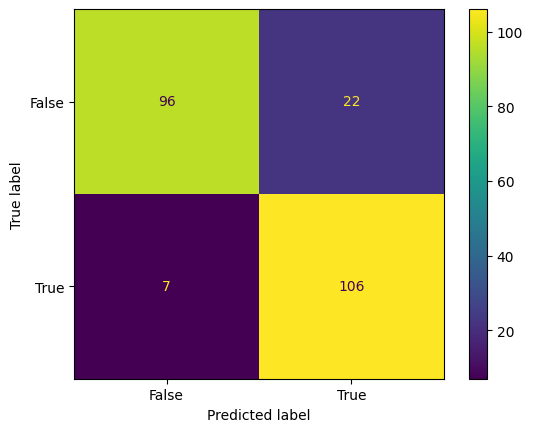

In [19]:
# Manually generating confusion matrix visualization.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([[96, 22], [7, 106]])

cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [False, True])

cm_display.plot()

plt.show()